# Piloto A/B simulado: ¿qué pasaría si se prueba el recomendador con una parte de los clientes?

**Autor:** Lookwise Data Lab
**Proyecto:** Sistema de recomendación para el e-commerce de H&M
**Notebook 07** · Continúa `06_metricas_optimizacion_decisiones.ipynb` · Plan completo en `docs/plan_validacion.md`

---

## Objetivo

Antes de llevar el recomendador a todos los clientes, el plan de validación propone un **piloto controlado (prueba A/B)**: una parte de los clientes ve las recomendaciones del modelo y el resto sigue viendo lo más vendido. Si el grupo del modelo compra más y la diferencia es significativa, se escala.

Como no tenemos acceso a la web de H&M, este notebook **simula el piloto con la semana de test (16 al 22/09/2020)**:

1. Reparte a los 4.162 clientes de esa semana en dos grupos con el **hash fijo** de `src/piloto.py`.
2. Verifica que los grupos sean **comparables** (edad y tipo de cliente).
3. Le asigna a cada grupo su vitrina: **modelo final** o **lo más vendido** (popularidad de 7 días).
4. Mide en cada grupo las mismas métricas que se medirían en producción y compara con un **intervalo de confianza del 95%**.
5. Aplica la **regla de escalado** del plan de validación.

| Grupo | Qué ve | Equivalente en producción |
|---|---|---|
| **Modelo** | Las 12 recomendaciones del modelo final por etapas (`models/recomendaciones_semana_test.csv`) | Vitrina personalizada |
| **Control** | Las 12 prendas más vendidas de los últimos 7 días | Lo que hace hoy la tienda |

**Diferencia con el notebook 06:** allí se compararon los modelos **sobre los mismos clientes**. Acá cada cliente ve **una sola vitrina**, como pasaría en un piloto real, y se comparan **grupos distintos**. Por eso importa que los grupos sean parecidos.

**Reproducibilidad:** no tiene componentes aleatorios. La asignación depende solo del `customer_id`, y las recomendaciones del modelo se leen de `models/`. Tarda menos de un minuto.

---
## Configuración

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("../src"))
from datos import cargar, tratar, separar, clientes_frios, CORTE_TEST
from metricas import compras_por_cliente, detalle_por_cliente
from modelos import PopularidadReciente
from piloto import asignar_grupo, tamano_muestra, balance_por_grupo, comparar_grupos, SAL_PILOTO

BASE = "../dataset/p10"   # carpeta local de la muestra p10 (no se versiona)
FIG_DIR, OUT_DIR, MODEL_DIR = "../reports/figures", "../reports", "../models"
os.makedirs(FIG_DIR, exist_ok=True)

GRIS, VERDE, TEXTO2 = "#9a9993", "#1baf7a", "#52514e"
COLOR = {"control": GRIS, "modelo": VERDE}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#d6d5cf",
    "axes.labelcolor": TEXTO2, "xtick.color": TEXTO2, "ytick.color": TEXTO2,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ecebe6", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "legend.frameon": False,
})
def guardar(fig, nombre):
    fig.savefig(f"{FIG_DIR}/{nombre}.png", bbox_inches="tight", facecolor="white")
print("Herramientas cargadas. Sal del piloto:", SAL_PILOTO)

Herramientas cargadas. Sal del piloto: lookwise-piloto


---
# 1. Datos del piloto simulado

**Qué hace:** repite el tratamiento y la partición de los notebooks anteriores (entrenamiento hasta el 15/09, test del 16 al 22/09) y lee las recomendaciones del modelo final guardadas en `models/`.

**Por qué se leen de `models/` y no se reentrena:** el piloto evalúa el modelo **tal como se desplegaría**. Usar el archivo guardado garantiza que es exactamente el mismo modelo seleccionado en el notebook 06.

In [2]:
trans, cust, art = cargar(BASE)
trans, cust, art, _ = tratar(trans, cust, art)
train, test = separar(trans, CORTE_TEST)

test = test.assign(article_id=test["article_id"].astype("int64"))
train = train.assign(article_id=train["article_id"].astype("int64"))
compras_test = compras_por_cliente(test)
frios = clientes_frios(trans, CORTE_TEST)

recs = pd.read_csv(f"{MODEL_DIR}/recomendaciones_semana_test.csv").sort_values(["customer_id", "posicion"])
recs_modelo = recs.groupby("customer_id")["article_id"].apply(list).to_dict()
faltan = set(compras_test) - set(recs_modelo)

clientes = pd.DataFrame({"customer_id": list(compras_test)})
clientes["segmento"] = np.where(clientes["customer_id"].isin(frios), "Nuevo", "Con historial")
clientes = clientes.merge(cust[["customer_id", "tramo_edad"]], on="customer_id", how="left")

print(f"{len(clientes):,} clientes compran en la semana de test "
      f"({(clientes['segmento'] == 'Nuevo').sum():,} nuevos y {(clientes['segmento'] == 'Con historial').sum():,} con historial).")
print(f"Recomendaciones del modelo final disponibles para {len(recs_modelo):,} clientes; "
      + ("todos los clientes del test tienen su lista." if not faltan else f"faltan {len(faltan):,}: revisar."))

4,162 clientes compran en la semana de test (437 nuevos y 3,725 con historial).
Recomendaciones del modelo final disponibles para 4,162 clientes; todos los clientes del test tienen su lista.


---
# 2. Asignación de los grupos con el hash

**Qué hace:** a cada cliente le calcula un número fijo entre 0 y 9.999 a partir de su `customer_id` (función `asignar_grupo` de `src/piloto.py`) y lo asigna al grupo **modelo** si el número queda por debajo del porcentaje elegido.

**Qué porcentaje se usa:**

- En producción, el piloto empieza con el **10%** de los clientes en el grupo modelo, para limitar el riesgo si el modelo funcionara peor.
- En esta simulación hay solo 4.162 clientes: con el 10% quedarían unos 400 en el grupo modelo. Por eso el escenario principal usa **50%**, que da la mayor precisión posible con estos clientes, y el escenario del **10%** se reporta como control de la etapa inicial real.

**Control de anidamiento:** al subir del 10% al 50%, todos los clientes que estaban en el grupo modelo deben seguir ahí. Es lo que permite escalar por etapas sin mover a nadie de grupo.

In [3]:
clientes["grupo_10"] = clientes["customer_id"].map(lambda c: asignar_grupo(c, 10))
clientes["grupo_50"] = clientes["customer_id"].map(lambda c: asignar_grupo(c, 50))

anidado = set(clientes.loc[clientes["grupo_10"] == "modelo", "customer_id"]) <= \
          set(clientes.loc[clientes["grupo_50"] == "modelo", "customer_id"])
repetible = all(asignar_grupo(c, 50) == g for c, g in zip(clientes["customer_id"].head(500), clientes["grupo_50"].head(500)))
reparto = pd.DataFrame({
    "Escenario": ["10% en el grupo modelo", "50% en el grupo modelo"],
    "Clientes grupo modelo": [(clientes["grupo_10"] == "modelo").sum(), (clientes["grupo_50"] == "modelo").sum()],
    "Clientes grupo control": [(clientes["grupo_10"] == "control").sum(), (clientes["grupo_50"] == "control").sum()],
})
reparto["% real en el grupo modelo"] = (reparto["Clientes grupo modelo"] / len(clientes) * 100).round(1)
print(f"Asignación anidada (los del 10% siguen en el 50%): {'Sí' if anidado else 'No'} · "
      f"misma asignación al repetir: {'Sí' if repetible else 'No'}")
reparto

Asignación anidada (los del 10% siguen en el 50%): Sí · misma asignación al repetir: Sí


,Escenario,Clientes grupo modelo,Clientes grupo control,% real en el grupo modelo
0,10% en el grupo modelo,425,3737,10.2
1,50% en el grupo modelo,2176,1986,52.3


**Interpretación**
- El porcentaje real de cada grupo queda cerca del elegido: el hash reparte a los clientes de forma pareja sin usar números aleatorios.
- La asignación es **anidada** y **repetible**: un cliente que vuelve a la web ve siempre la misma vitrina, y al escalar nadie cambia de grupo.

---
# 3. ¿Los grupos son comparables?

**Qué hace:** compara el reparto por tramo de edad y por tipo de cliente (nuevo o con historial) entre los dos grupos del escenario principal (50%).

**Por qué:** si un grupo tuviera más clientes con historial o más jóvenes, una diferencia en las compras podría deberse a eso y no a la vitrina. La edad se usa como **control**, no como criterio para elegir la muestra (ver `docs/plan_validacion.md`, sección 7.1).

In [4]:
balance_edad = balance_por_grupo(clientes.assign(grupo=clientes["grupo_50"]), "tramo_edad")
balance_seg = balance_por_grupo(clientes.assign(grupo=clientes["grupo_50"]), "segmento")
max_edad, max_seg = balance_edad["diferencia (puntos)"].max(), balance_seg["diferencia (puntos)"].max()
print(f"Mayor diferencia entre grupos: {max_edad:.1f} puntos en tramo de edad y {max_seg:.1f} puntos en tipo de cliente.")
print("   " + ("Los grupos son comparables: las diferencias son chicas." if max(max_edad, max_seg) < 5
             else "Hay diferencias de más de 5 puntos: se reportan los resultados por segmento para controlarlas."))
display(balance_edad)
display(balance_seg)

Mayor diferencia entre grupos: 1.2 puntos en tramo de edad y 0.8 puntos en tipo de cliente.
   Los grupos son comparables: las diferencias son chicas.


grupo,control,modelo,diferencia (puntos)
tramo_edad,,,
25-34,31.62,30.47,1.15
35-44,11.58,10.66,0.92
45-54,18.08,19.12,1.04
55+,12.84,12.50,0.34
<25,25.78,27.02,1.24
sin edad,0.10,0.23,0.13


grupo,control,modelo,diferencia (puntos)
segmento,,,
Con historial,89.93,89.11,0.82
Nuevo,10.07,10.89,0.82


---
# 4. Resultados del piloto simulado

**Qué hace:** cada cliente ve **solo la vitrina de su grupo**. Se mide:

| Métrica del piloto | Equivalente offline | Pregunta |
|---|---|---|
| **Conversión de la vitrina** (principal) | Hit Rate@12 | ¿Qué % de clientes compró al menos una prenda de su vitrina? |
| Prendas anticipadas | Recall@12 | ¿Qué parte de lo que compró estaba en su vitrina? |
| Diversidad | Prendas distintas | ¿Cuántas prendas distintas se mostraron? |

**Regla de escalado** (fijada en el plan de validación): se pasa a la etapa siguiente solo si la conversión del grupo modelo es mayor y el intervalo del 95% de la diferencia **no incluye el 0**.

In [5]:
baseline = PopularidadReciente(dias=7).fit(train, CORTE_TEST)
vitrina = {"modelo": lambda c: recs_modelo.get(c, baseline.top), "control": baseline.recomendar}

def medir(grupo_col):
    filas = []
    for g in ["modelo", "control"]:
        ids = clientes.loc[clientes[grupo_col] == g, "customer_id"]
        det, distintas = detalle_por_cliente({c: compras_test[c] for c in ids}, vitrina[g])
        det["grupo"] = g
        filas.append((det, distintas))
    detalle = pd.concat([d for d, _ in filas], ignore_index=True).merge(clientes[["customer_id", "segmento", "tramo_edad"]], on="customer_id")
    return detalle, {g: d for g, (_, d) in zip(["modelo", "control"], filas)}

def recall_ic(det, n=1000, semilla=42):
    rng = np.random.default_rng(semilla)
    m = det.loc[det["grupo"] == "modelo", "recall"].to_numpy(); c = det.loc[det["grupo"] == "control", "recall"].to_numpy()
    dif = [rng.choice(m, len(m)).mean() - rng.choice(c, len(c)).mean() for _ in range(n)]
    return m.mean() - c.mean(), *np.percentile(dif, [2.5, 97.5])

resumen = []
for esc, col in [("50% (principal)", "grupo_50"), ("10% (etapa inicial)", "grupo_10")]:
    det, distintas = medir(col)
    for seg in ["Todos", "Con historial", "Nuevo"]:
        d = det if seg == "Todos" else det[det["segmento"] == seg]
        cm = comparar_grupos(int(d.loc[d["grupo"] == "modelo", "hit"].sum()), int((d["grupo"] == "modelo").sum()),
                             int(d.loc[d["grupo"] == "control", "hit"].sum()), int((d["grupo"] == "control").sum()))
        r_dif, r_bajo, r_alto = recall_ic(d)
        resumen.append({"Escenario": esc, "Segmento": seg,
                        "Clientes modelo": int((d["grupo"] == "modelo").sum()), "Clientes control": int((d["grupo"] == "control").sum()),
                        "Conversión modelo (%)": cm["tasa_modelo"] * 100, "Conversión control (%)": cm["tasa_control"] * 100,
                        "Diferencia (puntos)": cm["diferencia"] * 100, "IC bajo": cm["ic_bajo"] * 100, "IC alto": cm["ic_alto"] * 100,
                        "Recall@12 modelo (%)": d.loc[d["grupo"] == "modelo", "recall"].mean() * 100,
                        "Recall@12 control (%)": d.loc[d["grupo"] == "control", "recall"].mean() * 100,
                        "Dif. Recall@12 (puntos)": r_dif * 100, "IC Recall bajo": r_bajo * 100, "IC Recall alto": r_alto * 100,
                        "¿Escalar?": "Sí" if cm["escalar"] else "No"})
    if col == "grupo_50":
        detalle_50, distintas_50 = det, distintas
resumen = pd.DataFrame(resumen).round(2)

p = resumen[(resumen["Escenario"] == "50% (principal)") & (resumen["Segmento"] == "Todos")].iloc[0]
print(f"Escenario principal (50%): la conversión pasa de {p['Conversión control (%)']:.1f}% con lo más vendido "
      f"a {p['Conversión modelo (%)']:.1f}% con el modelo ({p['Diferencia (puntos)']:+.1f} puntos, "
      f"IC 95% [{p['IC bajo']:+.1f}; {p['IC alto']:+.1f}]).")
print(f"   Decisión según la regla de escalado: {'escalar a la etapa siguiente' if p['¿Escalar?'] == 'Sí' else 'no escalar'}.")
print(f"   Prendas distintas mostradas: {distintas_50['modelo']:,} en el grupo modelo contra {distintas_50['control']:,} en el control.")
resumen

Escenario principal (50%): la conversión pasa de 6.5% con lo más vendido a 14.2% con el modelo (+7.6 puntos, IC 95% [+5.8; +9.4]).
   Decisión según la regla de escalado: escalar a la etapa siguiente.
   Prendas distintas mostradas: 2,874 en el grupo modelo contra 12 en el control.


,Escenario,Segmento,Clientes modelo,Clientes control,Conversión modelo (%),Conversión control (%),Diferencia (puntos),IC bajo,IC alto,Recall@12 modelo (%),Recall@12 control (%),Dif. Recall@12 (puntos),IC Recall bajo,IC Recall alto,¿Escalar?
0,50% (principal),Todos,2176,1986,14.15,6.55,7.61,5.78,9.43,7.16,2.44,4.72,3.72,5.76,Sí
1,50% (principal),Con historial,1939,1786,15.21,6.94,8.27,6.28,10.26,7.73,2.55,5.18,4.03,6.34,Sí
2,50% (principal),Nuevo,237,200,5.49,3.00,2.49,-1.26,6.23,2.54,1.46,1.08,-0.98,3.29,No
3,10% (etapa inicial),Todos,425,3737,13.65,6.90,6.74,3.38,10.11,6.39,2.73,3.66,1.85,5.63,Sí
4,10% (etapa inicial),Con historial,381,3344,14.44,7.21,7.23,3.59,10.86,6.69,2.83,3.86,1.88,6.01,Sí
5,10% (etapa inicial),Nuevo,44,393,6.82,4.33,2.49,-5.22,10.21,3.79,1.88,1.91,-1.83,7.37,No


### Gráfico: conversión de cada grupo por segmento

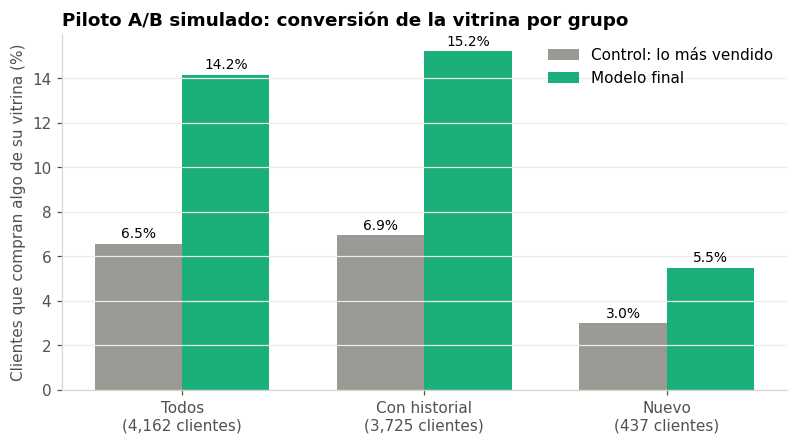

In [6]:
vista = resumen[resumen["Escenario"] == "50% (principal)"].set_index("Segmento").loc[["Todos", "Con historial", "Nuevo"]]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(vista)); ancho = 0.36
for j, (g, col) in enumerate([("control", "Conversión control (%)"), ("modelo", "Conversión modelo (%)")]):
    barras = ax.bar(x + (j - 0.5) * ancho, vista[col], ancho, color=COLOR[g],
                    label="Control: lo más vendido" if g == "control" else "Modelo final")
    ax.bar_label(barras, fmt="%.1f%%", fontsize=9, padding=2)
ax.set_xticks(x, [f"{s}\n({int(r['Clientes modelo'] + r['Clientes control']):,} clientes)" for s, r in vista.iterrows()])
ax.set_ylabel("Clientes que compran algo de su vitrina (%)")
ax.set_title("Piloto A/B simulado: conversión de la vitrina por grupo")
ax.legend(loc="upper right")
guardar(fig, "28_piloto_ab_conversion")
plt.show()

### Resultados por tramo de edad

**Qué hace:** repite la comparación de conversión dentro de cada tramo de edad del escenario principal.

**Por qué:** la edad no se usó para armar los grupos, pero sí sirve para revisar si el modelo funciona para todos. Con pocos clientes por tramo, los intervalos son más anchos: se leen como tendencia, no como prueba.

In [7]:
por_edad = []
for tramo, d in detalle_50.groupby("tramo_edad"):
    nm, nc = int((d["grupo"] == "modelo").sum()), int((d["grupo"] == "control").sum())
    if min(nm, nc) == 0:
        continue
    cm = comparar_grupos(int(d.loc[d["grupo"] == "modelo", "hit"].sum()), nm, int(d.loc[d["grupo"] == "control", "hit"].sum()), nc)
    por_edad.append({"Tramo de edad": tramo, "Clientes": nm + nc, "Conversión modelo (%)": cm["tasa_modelo"] * 100,
                     "Conversión control (%)": cm["tasa_control"] * 100, "Diferencia (puntos)": cm["diferencia"] * 100,
                     "IC bajo": cm["ic_bajo"] * 100, "IC alto": cm["ic_alto"] * 100,
                     "Mejora significativa": "Sí" if cm["escalar"] else "No concluyente"})
por_edad = pd.DataFrame(por_edad).round(2)
gana = (por_edad["Diferencia (puntos)"] > 0).sum()
print(f"El grupo modelo convierte más en {gana} de {len(por_edad)} tramos de edad.")
por_edad

El grupo modelo convierte más en 6 de 6 tramos de edad.


,Tramo de edad,Clientes,Conversión modelo (%),Conversión control (%),Diferencia (puntos),IC bajo,IC alto,Mejora significativa
0,25-34,1291,15.69,7.32,8.36,4.92,11.80,Sí
1,35-44,462,14.22,6.09,8.14,2.68,13.59,Sí
2,45-54,775,12.02,4.74,7.28,3.46,11.10,Sí
3,55+,527,12.13,7.06,5.07,0.08,10.07,Sí
4,<25,1100,14.80,6.84,7.96,4.35,11.57,Sí
5,sin edad,7,20.00,0.00,20.00,-15.06,55.06,No concluyente


---
# 5. ¿Cuántos clientes necesita el piloto real?

**Qué hace:** calcula con `tamano_muestra` cuántos clientes por grupo hacen falta para detectar distintas mejoras de conversión, con 95% de confianza y 80% de potencia, partiendo de la conversión del grupo control.

**Por qué:** un piloto demasiado chico puede no detectar una mejora real; uno demasiado grande expone a más clientes antes de tener evidencia.

In [8]:
tasa_control = p["Conversión control (%)"] / 100
filas = [{"Mejora mínima a detectar (puntos)": m * 100, "Clientes por grupo": tamano_muestra(tasa_control, m)}
         for m in [0.005, 0.01, 0.02, 0.05]]
observada = p["Diferencia (puntos)"] / 100
filas.append({"Mejora mínima a detectar (puntos)": round(observada * 100, 2), "Clientes por grupo": tamano_muestra(tasa_control, observada)})
tam = pd.DataFrame(filas)
print(f"Con la mejora observada en la simulación ({observada * 100:.1f} puntos) alcanzan unos {int(tam.iloc[-1]['Clientes por grupo']):,} clientes por grupo;")
print(f"para detectar una mejora más conservadora de 1 punto hacen falta {int(tam.iloc[1]['Clientes por grupo']):,} por grupo.")
tam

Con la mejora observada en la simulación (7.6 puntos) alcanzan unos 251 clientes por grupo;
para detectar una mejora más conservadora de 1 punto hacen falta 10,286 por grupo.


,Mejora mínima a detectar (puntos),Clientes por grupo
0,0.50,39794
1,1.00,10286
2,2.00,2739
3,5.00,516
4,7.61,251


---
# 6. Conclusiones

- **El piloto funciona como está diseñado:** el hash reparte a los clientes en grupos comparables, la asignación es repetible y anidada, y permite escalar por etapas sin mover a nadie de grupo.
- **Resultado:** los números de conversión, la diferencia entre grupos y su intervalo de confianza se imprimen en la sección 4 con los datos reales. La regla de escalado se aplica de forma automática.
- **Clientes nuevos:** en el modelo final, ambos grupos ven una vitrina de popularidad, así que no se espera diferencia. Es coherente con el notebook 06: el valor del modelo está en los clientes con historial.
- **Edad:** no se usó para armar los grupos; sirve para verificar que los grupos sean parecidos y para revisar el resultado por tramo.

### Limitaciones

- Es una **simulación con datos históricos**: los clientes no vieron realmente la vitrina, así que no mide el efecto causal de mostrarla (por ejemplo, que un cliente compre algo **porque** lo vio recomendado). Eso solo lo mide el piloto real.
- Una sola semana y 4.162 clientes: los intervalos por tramo de edad son anchos.
- En producción hay que sumar métricas que acá no existen: clics en la vitrina, ingreso por cliente y devoluciones.

---
# 7. Exportar resultados
**Qué hace:** guarda las tablas en `reports/` para el dashboard y la presentación.

In [9]:
resumen.to_csv(f"{OUT_DIR}/piloto_ab_simulado.csv", index=False, encoding="utf-8-sig")
por_edad.to_csv(f"{OUT_DIR}/piloto_ab_por_edad.csv", index=False, encoding="utf-8-sig")
tam.to_csv(f"{OUT_DIR}/piloto_tamano_muestra.csv", index=False, encoding="utf-8-sig")
print("Guardados piloto_ab_simulado.csv, piloto_ab_por_edad.csv y piloto_tamano_muestra.csv en reports/")

Guardados piloto_ab_simulado.csv, piloto_ab_por_edad.csv y piloto_tamano_muestra.csv en reports/
